# Are the climate-associated SVs transposons?

The GEA finds structural variants whose frequency tracks climate. This notebook asks what those variants
*are*, by joining them to the repeat classification of every SV record, insertions and deletions
(`r1_sv_negative_selection/TE_CLASSIFICATION_PIPELINE.md`: GraffiTE's masking protocol, applied to all
227,851 SV records).

## The hit list

**`v2_events_cr50`**, built 2026-10-02 — the current production GEA:

- **scans** LFMM ridge K = 16, generation 9, 352 pools, 22 axes (bio1–19, pc1–3), **raw p**, no GIF
  correction (lambda recorded, never applied)
- **unit** SV = a Truvari **event** (collapse 0.95/0.95/500 bp within a bubble and type)
- **filters** MAF ≥ 0.05 at gen-9 pool-mean frequency, **and called in ≥ 116 of 231 founders (50%)**
- **hit rule** Bonferroni 0.05 / n units per class × axis, union over scans
- **result** 20,134 SV events tested → **282 hits** (151 insertions, 131 deletions)

**The second run** is the archived `default_no_callrate` version: identical except with **no call-rate
floor** — 27,009 SV events tested → **355 hits**. It is here because the call-rate filter is not neutral
with respect to the question: the long-read panel is 78 of 231 founders (**34%**), so a variant called
only there cannot clear a 50% floor. If TE-rich variants are preferentially long-read-only, the
production run would be blind to exactly the class this notebook is about.

**Whether the hits are TE-enriched at all** is answered in `gea_hit_landscape.ipynb` §1b: against
everything the GEA tested, within size × MAF × replacement strata, with LD-block bootstrap CIs. This
notebook takes that as given and goes further: which families, where the hits land, what the call-rate
floor removes, and ONSEN.

## The join

**The join.** The GEA pool and our catalogue share `chrom` and `pos`, but 2.14% of panel positions carry
more than one record, so a position join silently matches the wrong allele. Every join here is on
**chrom + position + direction + size (within 5 bp)**, taking the best size match per unit, and units that
do not match uniquely are dropped rather than guessed at (251 of the 282 cr50 hits join).
`gea_hit_landscape.ipynb` joins through integer unit ids instead and places all 282.

In [1]:

import os, glob
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({"figure.dpi":120,"font.size":8,"axes.linewidth":0.6,"savefig.bbox":"tight","legend.frameon":False})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive")); os.makedirs(f"{G}/plots",exist_ok=True)
# colours: insertions forest green, deletions orange, SNPs grey; dark -> light = coding -> promoter -> intergenic
# (no blue or red: those are the garden-temperature scale)
PAL={"snp_CDS":"0.25","snp_promoter":"0.45","snp_intergenic":"0.65",
     "ins_CDS":"#2F4A1F","ins_promoter":"#4E6B3A","ins_intergenic":"#9DB58C",
     "del_CDS":"#B04A00","del_promoter":"#F07A2E","del_intergenic":"#F8BE91"}; PC=lambda t: PAL[t.split(":")[0]]         # colour of a term (interactions take their term's colour)
def style(a,axis="x"):
    a.set_axisbelow(True); a.grid(color="0.9",lw=0.6,axis=axis)
    for s_ in a.spines.values(): s_.set_visible(False)
def panel(a,letter,x=-0.08,y=1.04): a.annotate(letter,xy=(x,y),xycoords="axes fraction",fontsize=11,fontweight="bold",ha="right")
M="\u2212"
def pct(v,d=3): return f"{v:+.{d}g}%".replace("-",M)
NBPLOTS=os.path.join(os.getcwd(),"plots"); os.makedirs(NBPLOTS,exist_ok=True)          # notebooks/plots/, for the figures kept with the notebook
def save(fig,name,nb=False):
    for d in ([f"{G}/plots"]+([NBPLOTS] if nb else [])):
        fig.savefig(f"{d}/{name}.png",dpi=200,bbox_inches="tight"); fig.savefig(f"{d}/{name}.pdf",bbox_inches="tight")


In [2]:

import os
E=os.path.normpath(f"{G}/../../../genes/convergence/event_gea")
assert os.path.isdir(E), E
CAT=pd.read_csv(f"{G}/sv_event_catalog.csv")
# repeat class of every SV record, insertions AND deletions (TE_CLASSIFICATION_PIPELINE.md); an event takes
# the class of its representative record, which is the catalogue's `key`
RM=pd.read_csv(f"{G}/graffite/sv_repeat_class_records.csv").rename(columns={
    "span_te":"te_frac","top_family":"family","top_superfamily":"cls","top_div":"div"})
RM["repl"]=(RM.hprc_type=="COMPLEX")|(RM.unshared_bp>0)
assert CAT.key.isin(RM.key).all()
CTXC={"CDS":"#2F4A1F","UTR":"#4E6B3A","intron":"#7E9B6B","TE":"#C46A10",
      "promoter":"#5B7A99","intergenic":"#B9B9B9"}
def load_run(path):
    d=pd.read_csv(path)
    d["kd"]=np.where(d.kind=="insertion","ins","del")
    j=d.merge(CAT[["chrom","pos","size_bp","kind","key","context","n_called"]]
              .rename(columns={"kind":"kd","n_called":"cat_called"}),on=["chrom","pos","kd"],how="left")
    j["dsz"]=(j.size_bp-j["size"]).abs()
    j=j.sort_values("dsz").drop_duplicates("unit",keep="first")
    j=j[(j.dsz<=5)&j.key.notna()]
    return j.merge(RM[["key","te_frac","cargo","family","cls","div","repl","dominant"]],on="key",how="left")
RUNS={}
RUNS["cr50"]=load_run(f"{E}/cr50/event_sv_hits.csv")
RUNS["no call-rate"]=load_run(f"{E}/archive_default_no_callrate_2026-09-22/event_sv_hits.csv")
for k,v in RUNS.items():
    raw=pd.read_csv(f"{E}/cr50/event_sv_hits.csv" if k=="cr50"
                    else f"{E}/archive_default_no_callrate_2026-09-22/event_sv_hits.csv")
    print(f"{k:14s} tested {len(raw):,} SV events, {int(raw.hit.sum()):,} hits | "
          f"uniquely joined {len(v):,} ({100*len(v)/len(raw):.0f}%), of which hits {int(v.hit.sum())}")
TEHALF=["te_full","te_most"]


cr50           tested 20,134 SV events, 282 hits | uniquely joined 17,989 (89%), of which hits 251
no call-rate   tested 27,009 SV events, 355 hits | uniquely joined 24,184 (90%), of which hits 313


## 1 · Which families, and where the hits land

Two different statements that are easy to conflate: the **cargo** of a hit (what sequence the insertion
carries) and its **landing site** (what it inserted into, by the burden model's cascade). A variant can
carry a TE and land in a promoter, or carry nothing recognisable and land inside an annotated TE.

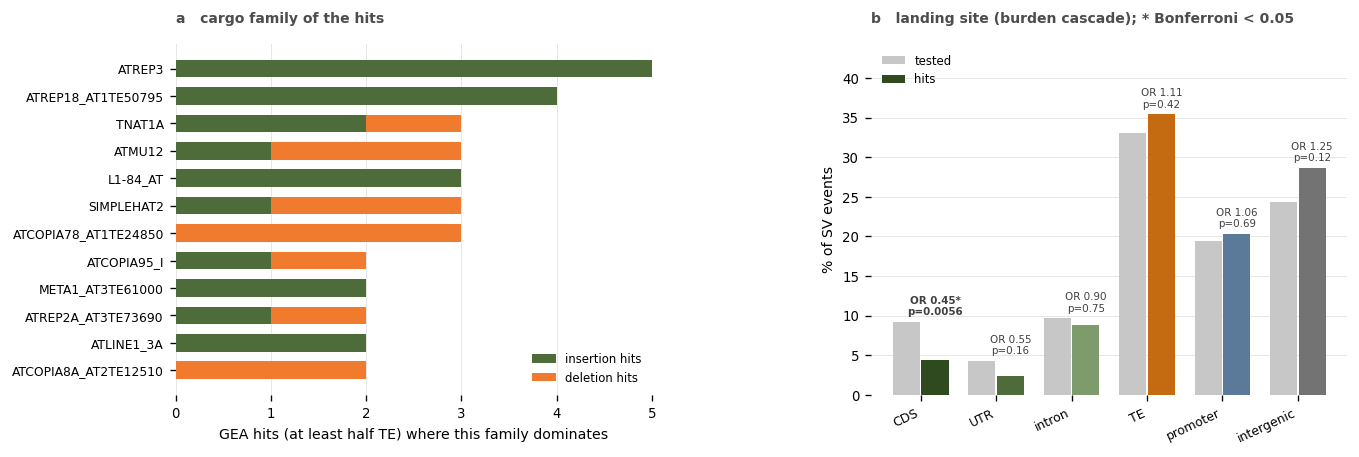

CARGO FAMILIES OF THE GEA HITS (cr50; hits at least half TE)

kd                    ins  del
family                        
ATREP3                  5    0
ATREP18_AT1TE50795      4    0
TNAT1A                  2    1
ATMU12                  1    2
L1-84_AT                3    0
SIMPLEHAT2              1    2
ATCOPIA78_AT1TE24850    0    3
ATCOPIA95_I             1    1
META1_AT3TE61000        2    0
ATREP2A_AT3TE73690      1    1
ATLINE1_3A              2    0
ATCOPIA8A_AT2TE12510    0    2

  ins: 71 TE hits, 58 families; most frequent family in 5 of them; superfamilies {'RC/Helitron': 13, 'LTR/Copia': 10, 'DNA/MULE-MuDR': 10, 'LTR/Gypsy': 8}

  del: 48 TE hits, 41 families; most frequent family in 3 of them; superfamilies {'RC/Helitron': 12, 'LTR/Copia': 9, 'DNA/MULE-MuDR': 9, 'LTR/Gypsy': 6}

LANDING SITE, hits vs the other tested events (cr50; Fisher, Bonferroni over 6 sites)

            hits  pct_hits  tested  pct_tested    OR       p  p_bonf
context                              

In [3]:

fig,axs=plt.subplots(1,2,figsize=(12.6,3.8),gridspec_kw=dict(wspace=0.46))
J=RUNS["cr50"]; H=J[J.hit]
a=axs[0]; style(a,axis="x")
FT=pd.crosstab(H[H.cargo.isin(TEHALF)].family,H[H.cargo.isin(TEHALF)].kd).reindex(columns=["ins","del"]).fillna(0)
FT=FT.loc[FT.sum(1).sort_values(ascending=False).index[:12]]
yy=np.arange(len(FT))[::-1]
a.barh(yy,FT["ins"].to_numpy(),color=PAL["ins_promoter"],height=0.64,label="insertion hits")
a.barh(yy,FT["del"].to_numpy(),left=FT["ins"].to_numpy(),color=PAL["del_promoter"],height=0.64,label="deletion hits")
a.set_yticks(yy); a.set_yticklabels(FT.index,fontsize=7.4); a.legend(fontsize=7,frameon=False,loc="lower right")
a.set_xlabel("GEA hits (at least half TE) where this family dominates",fontsize=8.5)
a.annotate("a   cargo family of the hits",xy=(0,1.06),xycoords="axes fraction",fontsize=8.4,
           fontweight="bold",color="0.3")
a=axs[1]; style(a,axis="y")
CX=["CDS","UTR","intron","TE","promoter","intergenic"]
hc=H.context.value_counts().reindex(CX).fillna(0)
bc=J[~J.hit].context.value_counts().reindex(CX).fillna(0)
# enrichment per landing site: Fisher, hits vs the other tested events, Bonferroni over the 6 sites
LS=[]
for c in CX:
    a1,b1=int(hc[c]),int(hc.sum()-hc[c]); c1,d1=int(bc[c]),int(bc.sum()-bc[c])
    orr,p=stats.fisher_exact([[a1,b1],[c1,d1]])
    LS.append(dict(context=c,hits=a1,pct_hits=100*a1/hc.sum(),tested=c1,pct_tested=100*c1/bc.sum(),
                   OR=orr,p=p,p_bonf=min(1,p*len(CX))))
LS=pd.DataFrame(LS).set_index("context")
x=np.arange(len(CX))
a.bar(x-0.19,100*bc/bc.sum(),width=0.36,color="0.78",label="tested")
a.bar(x+0.19,100*hc/hc.sum(),width=0.36,color=[CTXC[c] if c!="intergenic" else "0.45" for c in CX],label="hits")
for i,c in enumerate(CX):
    r=LS.loc[c]; star="*" if r.p_bonf<0.05 else ""
    a.annotate(f"OR {r.OR:.2f}{star}\np={r.p:.2g}",xy=(i+0.19,max(r.pct_hits,r.pct_tested)+0.6),ha="center",
               va="bottom",fontsize=6.2,color="0.25",fontweight="bold" if star else "normal")
a.set_ylim(0,1.25*float(max(LS.pct_hits.max(),LS.pct_tested.max())))
a.set_xticks(x); a.set_xticklabels(CX,fontsize=7.5,rotation=25,ha="right")
a.set_ylabel("% of SV events",fontsize=8.5); a.legend(fontsize=7,frameon=False,loc="upper left")
a.annotate("b   landing site (burden cascade); * Bonferroni < 0.05",xy=(0,1.06),xycoords="axes fraction",
           fontsize=8.4,fontweight="bold",color="0.3")
save(fig,"geate_families",nb=True); plt.show()
print("CARGO FAMILIES OF THE GEA HITS (cr50; hits at least half TE)\n"); print(FT.astype(int).to_string())
for kd in ("ins","del"):
    h=H[(H.kd==kd)&H.cargo.isin(TEHALF)]
    print(f"\n  {kd}: {len(h)} TE hits, {h.family.nunique()} families; most frequent family in "
          f"{h.family.value_counts().iloc[0]} of them; superfamilies {h.cls.value_counts().head(4).to_dict()}")
print("\nLANDING SITE, hits vs the other tested events (cr50; Fisher, Bonferroni over 6 sites)\n")
print(LS.round({"pct_hits":1,"pct_tested":1,"OR":2,"p":4,"p_bonf":4}).to_string())


## 2 · What the call-rate filter removes

The production GEA requires a variant to be called in ≥ 116 of 231 founders. The long-read panel is **78
founders (34%)**, so an SV detectable only from assemblies cannot clear that floor however real it is.
Since TE insertions are exactly the class most likely to be assembly-only, the filter could in principle
hide the signal this notebook is looking for.

Three things to check: how many events the floor removes, whether those events are cactus-panel-sized,
and whether they are more TE-rich than the ones that survive.

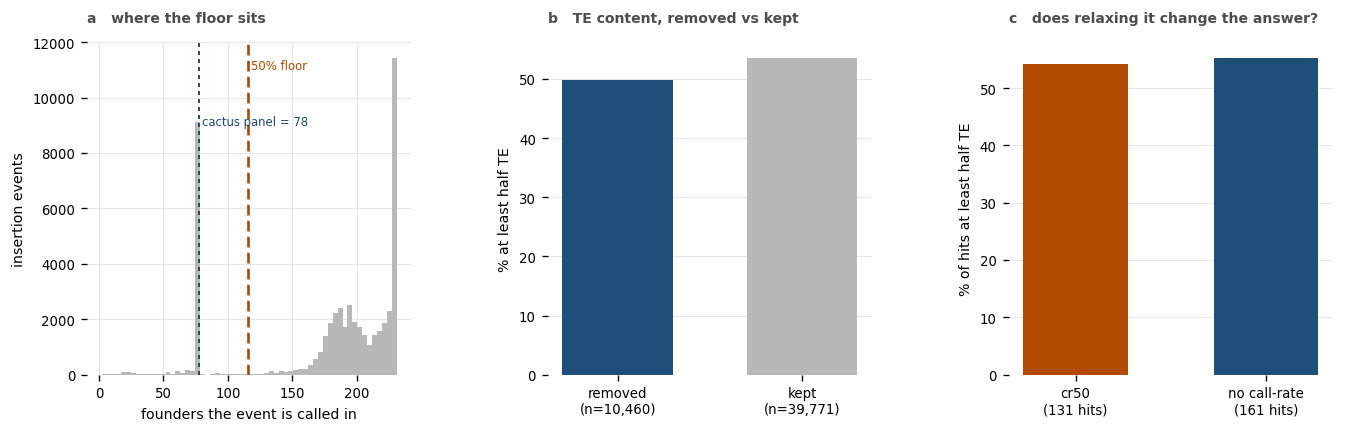

WHAT THE 50% CALL-RATE FLOOR REMOVES

  insertion events below the floor: 10,460 of 50,231 (20.8%)
  of those, called in <= 85 founders (cactus-panel sized): 10,231 (98% of the removed)

  >=half TE:  removed 49.9%   kept 53.6%
  mean TE fraction: removed 0.490   kept 0.522

  hit sets, % at least half TE: cr50 54.2% of 131, no call-rate 55.3% of 161


In [4]:

cc=CAT.merge(RM[["key","te_frac","cargo"]],on="key",how="left")
ins=cc[(cc.kind=="ins")&cc.te_frac.notna()]
lo=ins[ins.n_called<116]; hi=ins[ins.n_called>=116]
fig,axs=plt.subplots(1,3,figsize=(13.4,3.6),gridspec_kw=dict(wspace=0.42))
a=axs[0]; style(a,axis="both")
a.hist(ins.n_called,bins=60,color="0.72")
a.axvline(116,color="#B04A00",lw=1.6,ls=(0,(4,2)))
a.axvline(78,color="#1F4E79",lw=1.2,ls=(0,(2,2)))
a.annotate("50% floor",xy=(118,a.get_ylim()[1]*0.92),fontsize=7,color="#B04A00")
a.annotate("cactus panel = 78",xy=(80,a.get_ylim()[1]*0.75),fontsize=7,color="#1F4E79")
a.set_xlabel("founders the event is called in",fontsize=8.5); a.set_ylabel("insertion events",fontsize=8.5)
a.annotate("a   where the floor sits",xy=(0,1.06),xycoords="axes fraction",fontsize=8.4,
           fontweight="bold",color="0.3")
a=axs[1]; style(a,axis="y")
a.bar([0,1],[100*lo.cargo.isin(TEHALF).mean(),100*hi.cargo.isin(TEHALF).mean()],
      color=["#1F4E79","0.72"],width=0.6)
a.set_xticks([0,1]); a.set_xticklabels([f"removed\n(n={len(lo):,})",f"kept\n(n={len(hi):,})"],fontsize=8)
a.set_ylabel("% at least half TE",fontsize=8.5)
a.annotate("b   TE content, removed vs kept",xy=(0,1.06),xycoords="axes fraction",fontsize=8.4,
           fontweight="bold",color="0.3")
a=axs[2]; style(a,axis="y")
S=[]
for tag,J in RUNS.items():
    i2=J[(J.kd=="ins")&J.te_frac.notna()]
    S.append((tag,100*i2[i2.hit].cargo.isin(TEHALF).mean(),int(i2.hit.sum())))
a.bar(range(len(S)),[s[1] for s in S],color=["#B04A00","#1F4E79"],width=0.55)
a.set_xticks(range(len(S))); a.set_xticklabels([f"{s[0]}\n({s[2]} hits)" for s in S],fontsize=8)
a.set_ylabel("% of hits at least half TE",fontsize=8.5)
a.annotate("c   does relaxing it change the answer?",xy=(0,1.06),xycoords="axes fraction",
           fontsize=8.4,fontweight="bold",color="0.3")
save(fig,"geate_callrate",nb=True); plt.show()
print("WHAT THE 50% CALL-RATE FLOOR REMOVES\n")
print(f"  insertion events below the floor: {len(lo):,} of {len(ins):,} ({100*len(lo)/len(ins):.1f}%)")
print(f"  of those, called in <= 85 founders (cactus-panel sized): "
      f"{int((lo.n_called<=85).sum()):,} ({100*(lo.n_called<=85).mean():.0f}% of the removed)")
print(f"\n  >=half TE:  removed {100*lo.cargo.isin(TEHALF).mean():.1f}%   "
      f"kept {100*hi.cargo.isin(TEHALF).mean():.1f}%")
print(f"  mean TE fraction: removed {lo.te_frac.mean():.3f}   kept {hi.te_frac.mean():.3f}")
print("\n  hit sets, % at least half TE: " + ", ".join(f"{s[0]} {s[1]:.1f}% of {s[2]}" for s in S))


## 3 · Is any individual family enriched — and where is ONSEN?

The overall excess is modest and could be one family or many. This tests every family with at least 20
tested insertions, Fisher against all other tested insertions, Bonferroni over the families tested.

It also looks at a question the previous sections raise. ATCOPIA78 / ONSEN is the one family with a clear
climate signal in the **carrier** analysis (`sv_insertion_cargo_repeatmasker.ipynb` §6), so why is it
absent from the hit list? This is counted per insertion **event**, the project's SV unit, so one insertion
seen in several panel alleles counts once.

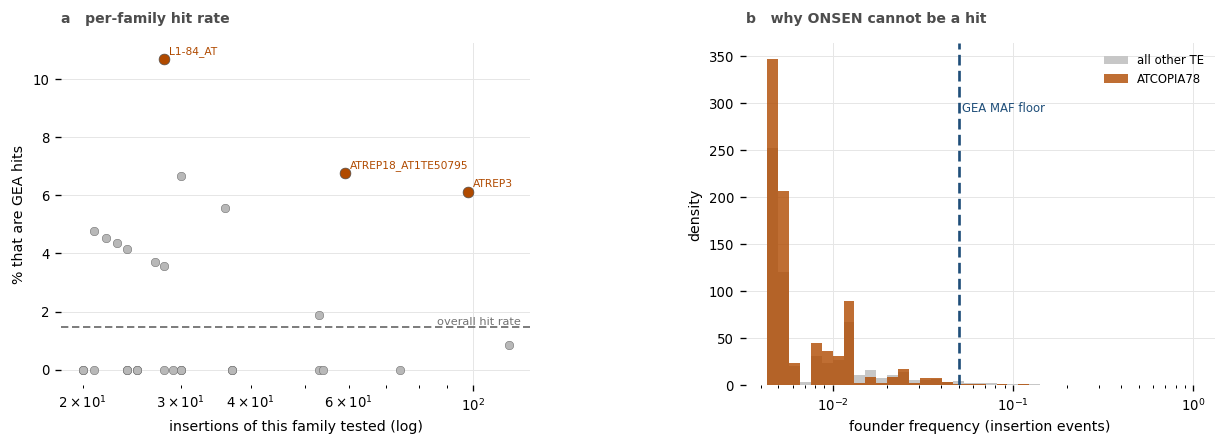

PER-FAMILY TEST  (29 families with >=20 tested insertions; overall hit rate 1.48%)

             family  n_tested  n_hits  hit_pct     OR      p  p_bonf
             ATREP3        98       6   6.1224 4.5104 0.0032  0.0932
           L1-84_AT        28       3  10.7143 8.1675 0.0079  0.2285
 ATREP18_AT1TE50795        59       4   6.7797 4.9718 0.0111  0.3208
   META1_AT3TE61000        30       2   6.6667 4.8223 0.0720  1.0000
         ATLINE1_3A        36       2   5.5556 3.9685 0.0986  1.0000
             ATN9_1        21       1   4.7619 3.3527 0.2687  1.0000
         ATTIR16T3A        22       1   4.5455 3.1927 0.2795  1.0000
ARNOLDY1_AT5TE31885        23       1   4.3478 3.0472 0.2902  1.0000
           ATTIRX1C        24       1   4.1667 2.9144 0.3007  1.0000
              AtSB2        27       1   3.7037 2.5772 0.3313  1.0000

  families passing Bonferroni: 0
  superfamilies of the nominal (p < 0.05) families: {'ATREP3': 'RC/Helitron', 'L1-84_AT': 'LINE/L1', 'ATREP18_AT1TE50795': 

In [5]:
J=RUNS["cr50"]; ins=J[(J.kd=="ins")&J.te_frac.notna()]
H=ins[ins.hit]; Bg=ins[~ins.hit]
rows=[]
for fam,g in ins.groupby("family"):
    if not isinstance(fam,str) or fam=="" or len(g)<20: continue
    a1=int(g.hit.sum()); b1=len(g)-a1
    orr,p=stats.fisher_exact([[a1,b1],[len(H)-a1,len(Bg)-b1]])
    rows.append(dict(family=fam,n_tested=len(g),n_hits=a1,hit_pct=100*a1/len(g),OR=orr,p=p))
T=pd.DataFrame(rows).sort_values("p")
T["p_bonf"]=np.minimum(1,T.p*len(T))
fig,axs=plt.subplots(1,2,figsize=(12.4,3.7),gridspec_kw=dict(wspace=0.46))
a=axs[0]; style(a,axis="both")
a.axhline(100*len(H)/len(ins),color="0.45",lw=1.1,ls=(0,(4,2)))
a.annotate("overall hit rate",xy=(0.98,100*len(H)/len(ins)),xycoords=("axes fraction","data"),
           ha="right",va="bottom",fontsize=6.8,color="0.45")
sig=T.p<0.05
a.scatter(T.loc[~sig,"n_tested"],T.loc[~sig,"hit_pct"],s=26,color="0.72",linewidth=0.3,edgecolor="0.4")
a.scatter(T.loc[sig,"n_tested"],T.loc[sig,"hit_pct"],s=42,color="#B04A00",linewidth=0.4,edgecolor="0.3")
for r in T[sig].itertuples():
    a.annotate(r.family[:18],xy=(r.n_tested,r.hit_pct),fontsize=6.4,color="#B04A00",
               xytext=(3,3),textcoords="offset points")
a.set_xscale("log"); a.set_xlabel("insertions of this family tested (log)",fontsize=8.5)
a.set_ylabel("% that are GEA hits",fontsize=8.5)
a.annotate("a   per-family hit rate",xy=(0,1.06),xycoords="axes fraction",fontsize=8.4,
           fontweight="bold",color="0.3")
a=axs[1]; style(a,axis="both")
# per EVENT (the project's SV unit), founder frequency = carriers / founders called. The GEA's MAF floor is
# on GrENE-Net pool frequency, so the founder frequency is a proxy for it, not the same quantity
CE=CAT[CAT.kind=="ins"].merge(RM[["key","family","te_frac"]],on="key",how="left")
CE["freq"]=CE.n_carriers/CE.n_called
is78=CE.family.astype(str).str.contains("ATCOPIA78",na=False)
A78=CE[is78]; other=CE[(CE.te_frac>0)&~is78]
bins=np.logspace(np.log10(1/231),0,40)
a.hist(other.freq.dropna(),bins=bins,density=True,color="0.78",label="all other TE")
a.hist(A78.freq.dropna(),bins=bins,density=True,color="#B04A00",alpha=0.8,label="ATCOPIA78")
a.axvline(0.05,color="#1F4E79",lw=1.6,ls=(0,(4,2)))
a.annotate("GEA MAF floor",xy=(0.052,a.get_ylim()[1]*0.8),fontsize=7,color="#1F4E79")
a.set_xscale("log"); a.set_xlabel("founder frequency (insertion events)",fontsize=8.5)
a.set_ylabel("density",fontsize=8.5); a.legend(fontsize=7,frameon=False)
a.annotate("b   why ONSEN cannot be a hit",xy=(0,1.06),xycoords="axes fraction",fontsize=8.4,
           fontweight="bold",color="0.3")
save(fig,"geate_family_test",nb=True); plt.show()
print(f"PER-FAMILY TEST  ({len(T)} families with >=20 tested insertions; "
      f"overall hit rate {100*len(H)/len(ins):.2f}%)\n")
print(T.head(10).round(4).to_string(index=False))
print(f"\n  families passing Bonferroni: {int((T.p_bonf<0.05).sum())}")
print(f"  superfamilies of the nominal (p < 0.05) families: "
      f"{ins[ins.family.isin(T[T.p<0.05].family)].drop_duplicates('family').set_index('family').cls.to_dict()}")
print("\nWHY ATCOPIA78 / ONSEN IS ABSENT FROM THE HIT LIST  (per insertion EVENT)\n")
print(f"  ATCOPIA78 insertion events in the panel: {len(A78):,}")
print(f"    median carriers {A78.n_carriers.median():.0f}, median founder frequency {A78.freq.median():.4f}")
print(f"    founder frequency >= 0.05: {int((A78.freq>=0.05).sum()):,} ({100*(A78.freq>=0.05).mean():.1f}%)")
print(f"  all other TE insertion events with founder frequency >= 0.05: {100*(other.freq>=0.05).mean():.1f}%")
n78={k:int((J_.kd.eq("ins")&J_.family.astype(str).str.contains("ATCOPIA78")).sum()) for k,J_ in RUNS.items()}
print(f"  ATCOPIA78 events tested by the GEA: " + ", ".join(f"{k} {v}" for k,v in n78.items()))


## 4 · Reading it

**Enrichment is in `gea_hit_landscape.ipynb` §1b.** In short: insertion hits are TE-enriched against
everything tested (53.6% vs 44.3% at least half TE, stratified OR 1.67, CI 1.16–2.36); deletion hits are
not (OR 1.16, CI 0.76–1.68). This notebook takes that as given.

**Where the hits land: depleted from coding sequence, enriched nowhere.** 4.4% of hits fall in CDS against
9.2% of tested events (OR 0.45, Bonferroni p = 0.034), the only site that survives correction. Hits inside
annotated TEs (35.5% vs 33.0%) and in promoters (20.3% vs 19.4%) are at background. So hits *carry* TE
sequence more often than expected, but they do not *land* in TEs more often. The two are separate
properties. This test pools both directions and is unstratified; the stratified, per-direction version is
`gea_hit_landscape.ipynb` §2.

**No single family drives it.** The 71 insertion hits that are at least half TE come from 58 families;
the most frequent appears 5 times. No family passes Bonferroni. The nominal top three are ATREP3
(RC/Helitron), L1-84_AT (LINE/L1) and ATREP18 (labelled plain `DNA` in the TAIR10 part of the library,
although most ATREP families there are Helitrons). RC/Helitron is the commonest superfamily among both
insertion and deletion hits.

**The call-rate floor is not hiding TE-rich variants.** It removes 10,460 insertion events, 98% of them
called in ≤ 85 founders, i.e. assembly-only as expected. These are slightly *less* TE-rich than the
events that survive (49.9% vs 53.6%), the opposite of the worry that motivated the second run. The
earlier `-nolow` classification showed them as slightly *more* TE-rich (60.7% vs 56.9%). The sign flips
because assembly-only events lose more whole-TE calls under the new masking than the rest do, and that
happens among their clean records, not only among replacements. A gap this small rests on the masking
protocol, so read it as "no TE excess among the removed events", not as a depletion.

**ONSEN is rare, not invisible.** Counted per event, there are 298 ATCOPIA78 insertion events. Their median
founder frequency is 0.010, and 7.7% reach 0.05, against 24.3% of other TE insertion events. Eight
were tested by the cr50 GEA (14 without the call-rate floor) and none is a hit. ONSEN does appear on the
other side: three cr50 **deletion** hits remove an ATCOPIA78 copy that Col-0 carries.

**What is still missing**
- **Direction.** This asks what the hits *are*, not which way their frequency moves with climate. Pairing
  cargo with the sign of the climate association is the obvious next step.
- **Polarity.** An insertion relative to Col-0 is not necessarily new. Target site duplications, now
  available per record after the GraffiTE flank fix (`tsd_status` in the classification table), can
  resolve this for single-copy, clean TE insertions; they are not used here yet.
- **The hit list is a candidate net.** Raw uncalibrated LFMM p, climate-structured hits, no GIF
  correction, as the GEA manifest states. Nothing here is a calibrated enrichment test of that list.

## As run

- **GEA**: `genes/convergence/event_gea/cr50/event_sv_hits.csv` (production, 50% call-rate floor) and
  `archive_default_no_callrate_2026-09-22/event_sv_hits.csv` (no floor). Both carry a `hit` column from
  the Bonferroni rule; `p_bar` in those files is **allele frequency, not a p-value**.
- **Cargo**: `graffite/sv_repeat_class_records.csv`, built by the pipeline in
  `r1_sv_negative_selection/TE_CLASSIFICATION_PIPELINE.md`. RepeatMasker `-s` against TAIR10 + RepBase
  31.09, low-complexity masking on (GraffiTE's protocol), on the ALT of insertions and the REF of
  deletions. TE fraction = union of TE-class hits / allele length; simple repeat, low complexity and
  satellite do not count as TE. An event takes the class of its representative record (the catalogue
  `key`). Until 2026-10-04 this read `rm_cargo_allins.csv` (`-nolow`, insertions only).
- **Landing-site enrichment**: per site, Fisher's exact test of hits vs the other tested events (cr50,
  both directions pooled), Bonferroni over the six sites. Unstratified; the size × MAF-stratified,
  block-bootstrapped version by direction is `gea_hit_landscape.ipynb` §2 (its region classifier differs).
- **Join**: chrom + position + direction + size within 5 bp, best size match per unit, non-unique matches
  dropped. Never on position alone — 2.14% of panel positions carry more than one record.
- **Landing site** is the burden model's cascade (`context` in `sv_event_catalog.csv`), not the older
  `genic` scheme.